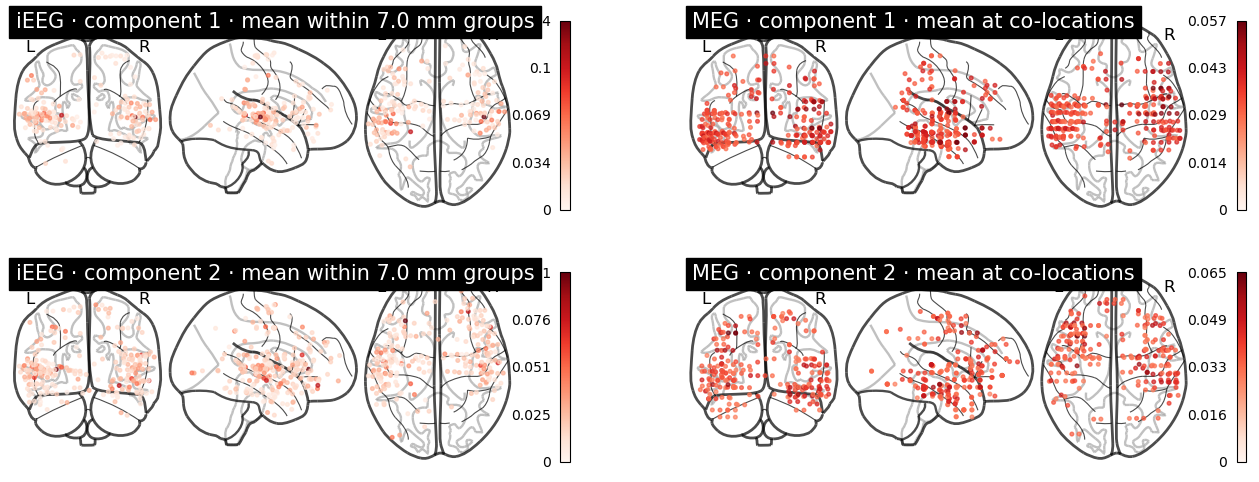

106

In [ ]:
from vs3_1_modality_specificity import estimate_meg_spacing, average_spatial_groups
IEEG_DISPLAY_RADIUS_MM = None  # automatic MEG spacing; or explicit mm, e.g. 5.
meg_spacing_mm, meg_spacing_audit = estimate_meg_spacing(datasets['MEG'])
ieeg_display_radius_mm = meg_spacing_mm if IEEG_DISPLAY_RADIUS_MM is None else IEEG_DISPLAY_RADIUS_MM
brain_fig = plot_thresholded_brains(datasets, retained, ieeg_radius_mm=ieeg_display_radius_mm)
plt.show()
OUTPUT.mkdir(parents=True, exist_ok=True)
meg_spacing_audit.to_csv(OUTPUT / 'meg_spacing_audit.csv', index=False)
_, _, display_groups = average_spatial_groups(retained['iEEG'], datasets['iEEG'].metadata[['x','y','z']].to_numpy(), radius_mm=ieeg_display_radius_mm)
display_groups.to_csv(OUTPUT / 'ieeg_display_groups.csv', index=False)
(OUTPUT / 'brain_display_configuration.json').write_text(json.dumps(dict(ieeg_radius_mm=ieeg_display_radius_mm, grouping='complete_linkage', mean_includes_zeros=True), indent=2))


[fetch_atlas_aal] Dataset found in /users/barbara/nilearn_data/aal_SPM12

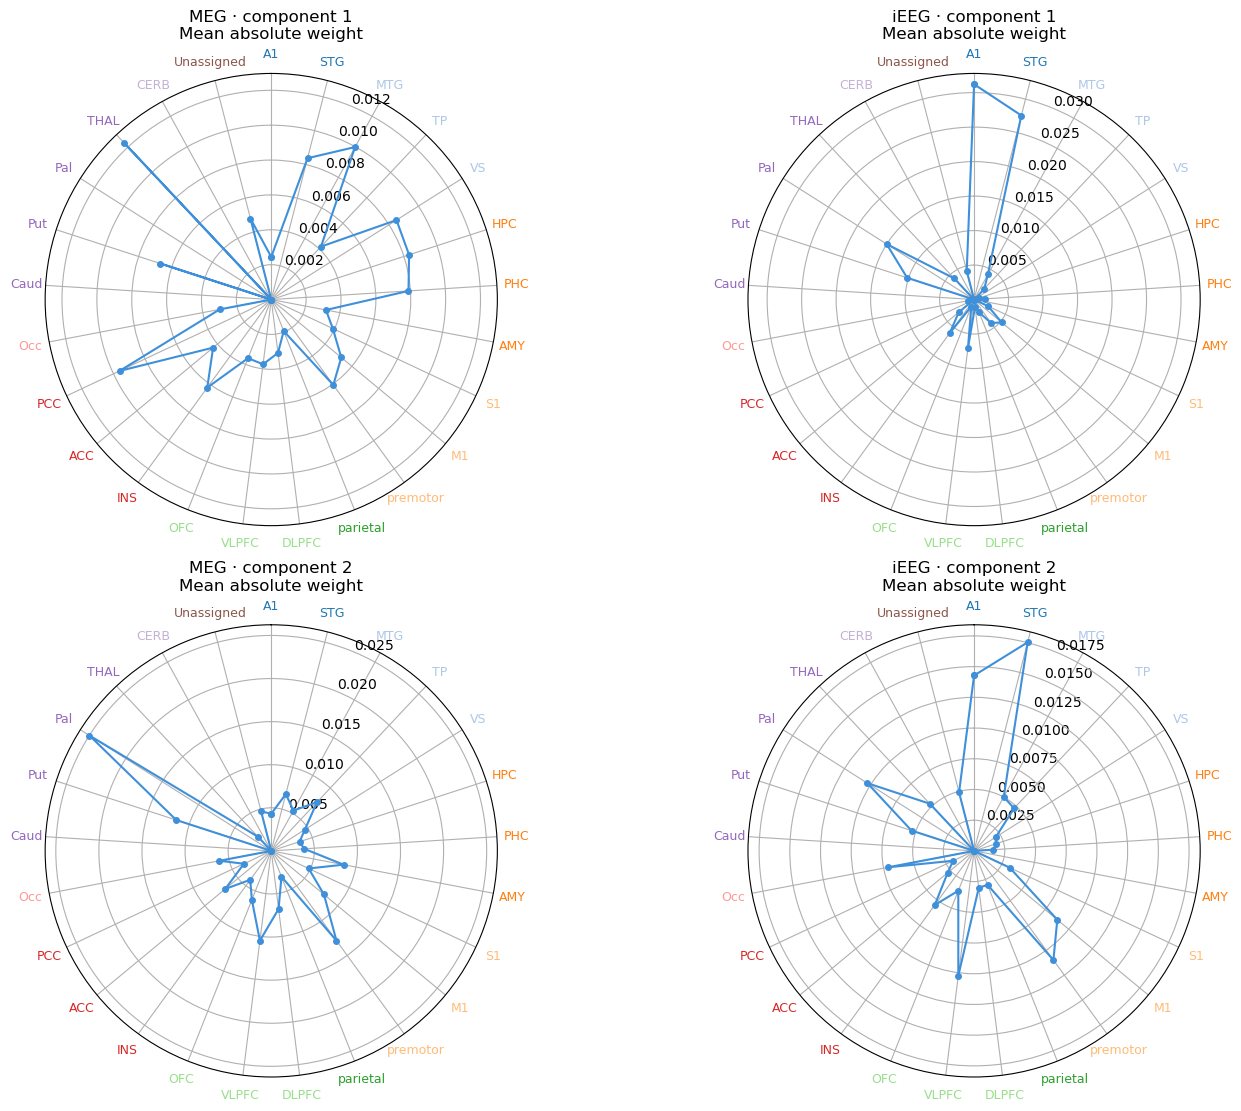

In [ ]:
from vs3_1_modality_specificity import regional_weight_summary, plot_regional_weight_polar, shared_coordinate_regions
REGION_USE_THRESHOLDED = True
shared_region_metadata = shared_coordinate_regions(datasets)
for modality, metadata in shared_region_metadata.items():
    metadata.to_csv(OUTPUT / f'{modality.lower()}_shared_region_labels.csv', index=False)
region_table = regional_weight_summary(retained if REGION_USE_THRESHOLDED else weights, datasets,
                                       labelled_metadata=shared_region_metadata)
region_table['weight_input'] = 'thresholded' if REGION_USE_THRESHOLDED else 'original'
region_fig = plot_regional_weight_polar(region_table)
region_table.to_csv(OUTPUT / 'regional_weight_summary.csv', index=False)


/users/barbara/miniforge3/envs/mne_iEEG/lib/python3.10/site-packages/nilearn/surface/surface.py:603: RuntimeWarning: Mean of empty slice
  texture = np.nanmean(all_samples, axis=2)
/users/barbara/miniforge3/envs/mne_iEEG/lib/python3.10/site-packages/nilearn/surface/surface.py:603: RuntimeWarning: Mean of empty slice
  texture = np.nanmean(all_samples, axis=2)


/users/barbara/miniforge3/envs/mne_iEEG/lib/python3.10/site-packages/nilearn/surface/surface.py:603: RuntimeWarning: Mean of empty slice
  texture = np.nanmean(all_samples, axis=2)
/users/barbara/miniforge3/envs/mne_iEEG/lib/python3.10/site-packages/nilearn/surface/surface.py:603: RuntimeWarning: Mean of empty slice
  texture = np.nanmean(all_samples, axis=2)
/users/barbara/miniforge3/envs/mne_iEEG/lib/python3.10/site-packages/nilearn/surface/surface.py:603: RuntimeWarning: Mean of empty slice
  texture = np.nanmean(all_samples, axis=2)
/users/barbara/miniforge3/envs/mne_iEEG/lib/python3.10/site-packages/nilearn/surface/surface.py:603: RuntimeWarning: Mean of empty slice
  texture = np.nanmean(all_samples, axis=2)
/users/barbara/miniforge3/envs/mne_iEEG/lib/python3.10/site-packages/nilearn/surface/surface.py:603: RuntimeWarning: Mean of empty slice
  texture = np.nanmean(all_samples, axis=2)
/users/barbara/miniforge3/envs/mne_iEEG/lib/python3.10/site-packages/nilearn/surface/surface.py

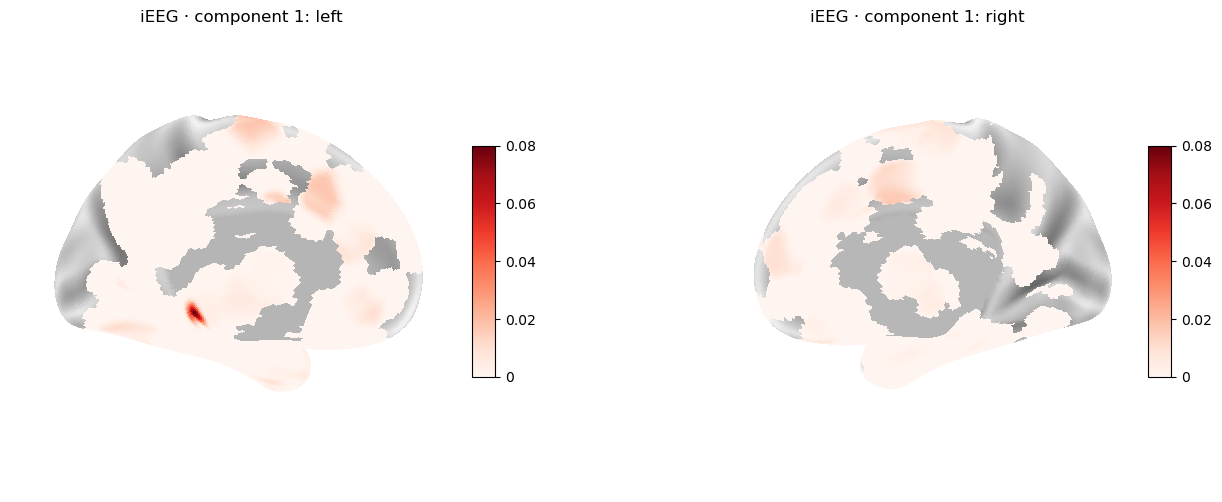

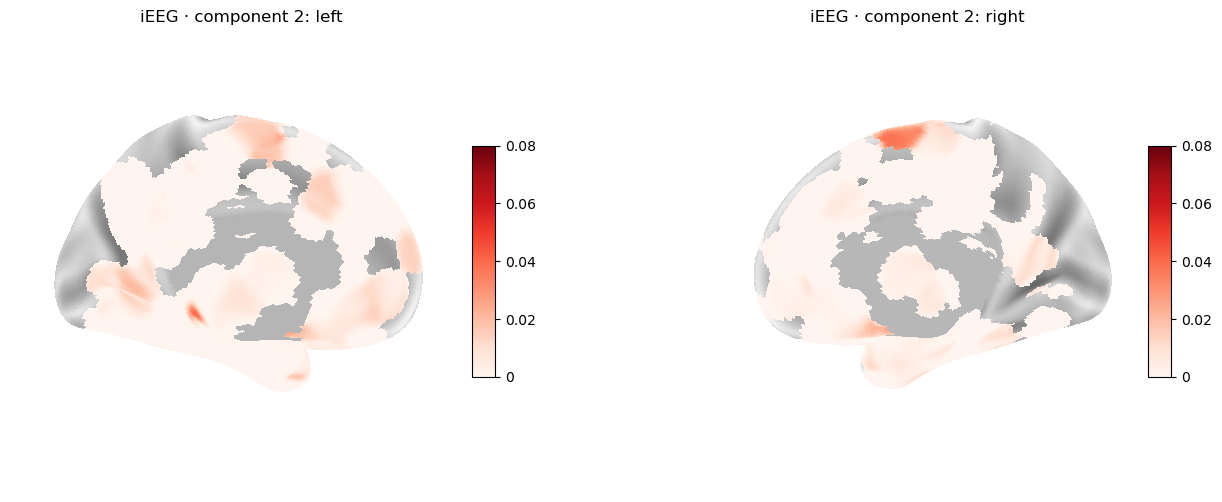

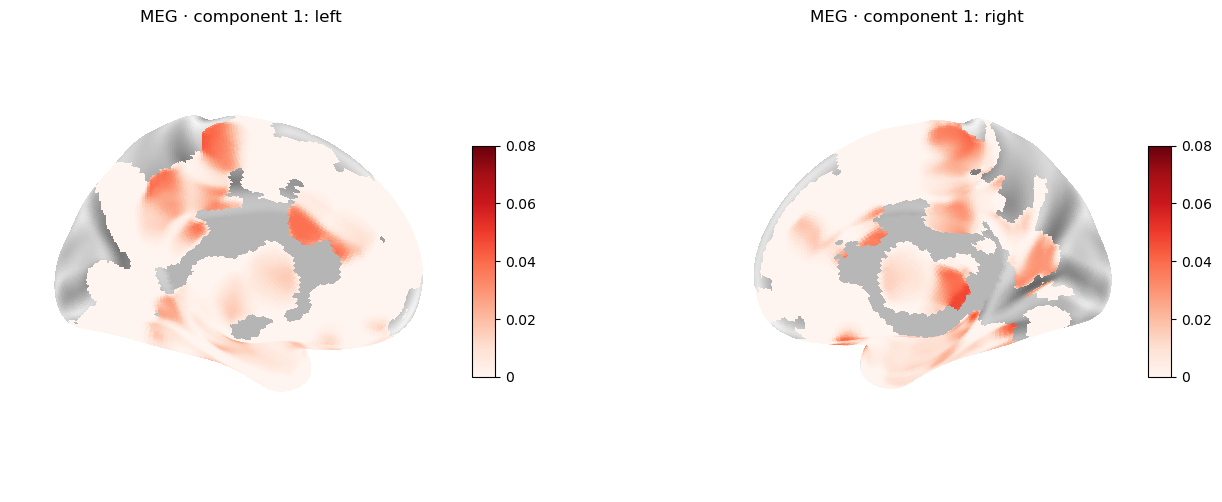

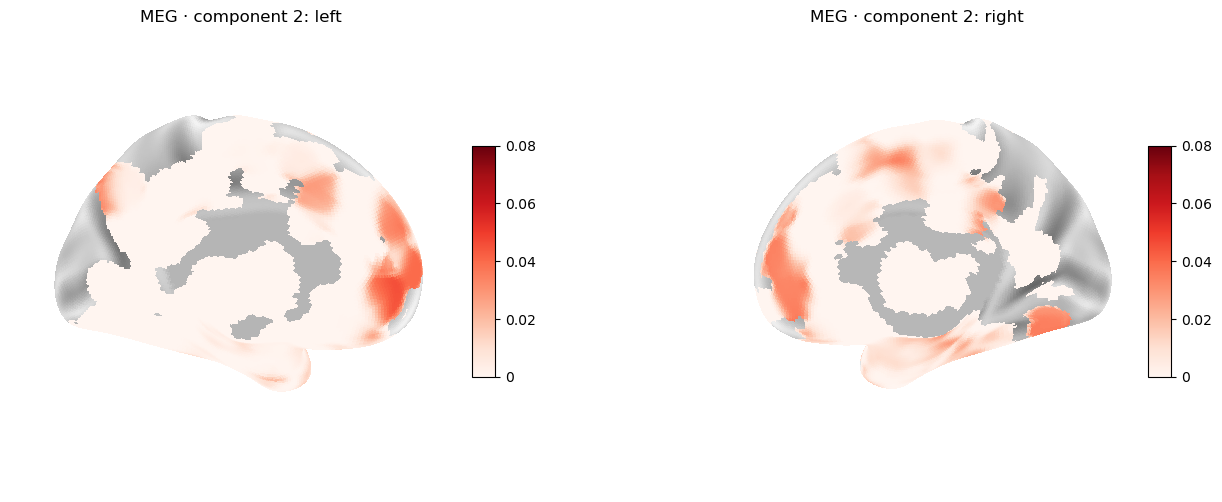

192

In [ ]:
from vs3_1_modality_specificity import plot_modality_glasser
SURFACE_USE_THRESHOLDED = True
SURFACE_SIGMA_MM = 4.
SURFACE_VMIN = 0
SURFACE_VMAX = 0.08  
SURFACE_VIEW = 'medial'  # alternatively 'medial'
SURFACE_OUTPUT = OUTPUT / ('surface_folded_' + TARGET_HEMISPHERE if FOLD_HEMISPHERES else 'surface_bilateral')
SURFACE_OUTPUT.mkdir(parents=True, exist_ok=True)
for modality, component, surface_fig in plot_modality_glasser(
        datasets, retained if SURFACE_USE_THRESHOLDED else {name: np.abs(w) for name,w in weights.items()},
        ieeg_radius_mm=ieeg_display_radius_mm, sigma=SURFACE_SIGMA_MM, view=SURFACE_VIEW,
        vmin=SURFACE_VMIN, vmax=SURFACE_VMAX,
        fold_hemispheres=FOLD_HEMISPHERES, target_hemisphere=TARGET_HEMISPHERE):
    display(surface_fig)
    surface_fig.savefig(SURFACE_OUTPUT / f'glasser_{modality.lower()}_component_{component}_{SURFACE_VIEW}.png', dpi=180, bbox_inches='tight')
    plt.close(surface_fig)
(SURFACE_OUTPUT / 'surface_configuration.json').write_text(json.dumps(dict(thresholded=SURFACE_USE_THRESHOLDED,
    fold_hemispheres=FOLD_HEMISPHERES, target_hemisphere=TARGET_HEMISPHERE,
    sigma_mm=SURFACE_SIGMA_MM, view=SURFACE_VIEW, vmin=SURFACE_VMIN, vmax=SURFACE_VMAX, ieeg_radius_mm=ieeg_display_radius_mm), indent=2))
